# Descriptive analysis

`notebooks/01-data-cleaning.ipynb` already recorded the 15-column schema, the missing-value counts, and the four-column cleaning. This notebook does not repeat that pass.

It stays on `data/raw/digikala-comments.csv`. `recommendation_status`, `is_buyer`, and `seller_code` are not in the cleaned CSV, and the project asks for those counts on the complete parsed file. A review body can contain newlines, so the row count comes from the CSV parser.

Every count uses all parsed rows. The plots are bar charts of those full-file bins. There is no row sample and no sampling seed.

Rating bands, unchanged from the project brief:

- `low`: 0 ≤ rate < 2.5
- `medium`: 2.5 ≤ rate < 4
- `high`: 4 ≤ rate ≤ 5
- `invalid`: missing, or outside [0, 5]

Word length is a whitespace split after line breaks and repeated spaces are collapsed. It is not an encoder token count. Vocabulary counts are left out; the brief marks them optional.

In [38]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl

pl.Config.set_tbl_rows(20)
pl.Config.set_tbl_cols(12)

RAW = Path("../data/raw/digikala-comments.csv")
NA_VALUES = ["", "nan", "NaN", "NAN", "null", "NULL", "None", "none", "-"]
COLUMNS = [
    "id",
    "body",
    "rate",
    "recommendation_status",
    "is_buyer",
    "product_id",
    "seller_code",
]
LABELS = ["recommended", "no_idea", "not_recommended"]
BANDS = ["low", "medium", "high"]
BUCKETS = ["1", "2-5", "6-20", "21-100", "101+"]
WORD_BINS = ["1", "2-3", "4-5", "6-10", "11-20", "21-40", "41-80", "81-160", "161+"]


def rating_band(rate: pl.Expr) -> pl.Expr:
    """Map a raw rate onto the project bands. Rate 0 stays in low."""
    return (
        pl.when(rate.is_null() | (rate < 0) | (rate > 5))
        .then(pl.lit("invalid"))
        .when(rate < 2.5)
        .then(pl.lit("low"))
        .when(rate < 4.0)
        .then(pl.lit("medium"))
        .otherwise(pl.lit("high"))
    )


def count_bucket(count: pl.Expr) -> pl.Expr:
    """Bucket a review count so the product distribution can be plotted."""
    return (
        pl.when(count == 1).then(pl.lit("1"))
        .when(count <= 5).then(pl.lit("2-5"))
        .when(count <= 20).then(pl.lit("6-20"))
        .when(count <= 100).then(pl.lit("21-100"))
        .otherwise(pl.lit("101+"))
    )


def word_bin(words: pl.Expr) -> pl.Expr:
    return (
        pl.when(words <= 1).then(pl.lit("1"))
        .when(words <= 3).then(pl.lit("2-3"))
        .when(words <= 5).then(pl.lit("4-5"))
        .when(words <= 10).then(pl.lit("6-10"))
        .when(words <= 20).then(pl.lit("11-20"))
        .when(words <= 40).then(pl.lit("21-40"))
        .when(words <= 80).then(pl.lit("41-80"))
        .when(words <= 160).then(pl.lit("81-160"))
        .otherwise(pl.lit("161+"))
    )


def order_by(frame: pl.DataFrame, column: str, order: list[str]) -> pl.DataFrame:
    return frame.with_columns(pl.col(column).cast(pl.Enum(order))).sort(column)


reviews = (
    pl.scan_csv(RAW, null_values=NA_VALUES)
    .select(COLUMNS)
    .with_columns(
        pl.col("body")
        .fill_null("")
        .str.replace_all(r"\s+", " ")
        .str.strip_chars()
        .alias("body_norm")
    )
    .with_columns(
        pl.col("body_norm").str.len_chars().alias("char_len"),
        pl.when(pl.col("body_norm") == "")
        .then(0)
        .otherwise(pl.col("body_norm").str.split(" ").list.len())
        .alias("word_len"),
        rating_band(pl.col("rate")).alias("rating_band"),
        pl.col("recommendation_status").is_null().alias("label_missing"),
    )
)

## Products and sellers

Unique products, unique sellers, and how unevenly reviews sit on products. A later grouped split exists so one product cannot land in both train and test. The concentration numbers are the reason that split is required.

Notebook 01 found the same missing count on `seller_title` and `seller_code`. The cross-tab below checks whether that missing seller block is exactly the non-buyer rows.

In [39]:
from IPython.display import HTML, display
display(HTML(
    "<h3>Parsed file</h3>"
    "<p>One row of the raw comments CSV. products and sellers are distinct ids. rows_missing_seller counts reviews with no seller code. empty_bodies counts reviews whose text is blank after spaces and line breaks are collapsed. file_bytes is the size of the CSV on disk.</p>"
))
size = reviews.select(
    pl.len().alias("rows"),
    pl.col("product_id").n_unique().alias("products"),
    pl.col("seller_code").drop_nulls().n_unique().alias("sellers"),
    pl.col("seller_code").null_count().alias("rows_missing_seller"),
    (pl.col("body_norm") == "").sum().alias("empty_bodies"),
).collect()
size = size.with_columns(pl.lit(RAW.stat().st_size).alias("file_bytes"))
size

rows,products,sellers,rows_missing_seller,empty_bodies,file_bytes
u32,u32,u32,u32,u32,i32
6156289,331599,29213,302181,637,1278526959


In [40]:
from IPython.display import HTML, display
display(HTML(
    "<h3>Buyer flag and missing seller are the same split</h3>"
    "<p>There are four possible pairings. rows is how many reviews have that pairing. A zero means that pairing never occurs. In this file the two flags mark the same reviews: every missing seller is a non-buyer, and every recorded seller is a buyer.</p>"
))
pairs = pl.DataFrame(
    {
        "is_buyer": [False, False, True, True],
        "seller_missing": [False, True, False, True],
    }
)
seller_by_buyer = (
    reviews.group_by(
        "is_buyer",
        pl.col("seller_code").is_null().alias("seller_missing"),
    )
    .agg(pl.len().alias("rows"))
    .collect()
)
seller_by_buyer = (
    pairs.join(seller_by_buyer, on=["is_buyer", "seller_missing"], how="left")
    .with_columns(pl.col("rows").fill_null(0).cast(pl.UInt32))
    .sort("is_buyer", "seller_missing")
)
seller_by_buyer

is_buyer,seller_missing,rows
bool,bool,u32
false,false,0
false,true,302181
true,false,5854108
true,true,0


| is_buyer | seller_missing | rows | what it means |
| --- | --- | ---: | --- |
| false | false | 0 | a non-buyer who still has a seller — never happens |
| false | true | 302,181 | every review with no seller is a non-buyer |
| true | false | 5,854,108 | every review that has a seller is a buyer |
| true | true | 0 | a buyer with no seller — never happens |

In [41]:
from IPython.display import HTML, display
display(HTML(
    "<h3>How many reviews each product has</h3>"
    "<p>products is the number of distinct product ids. min, median, mean, p75, p90, p99, and max describe the review count of one product. products_with_one_review counts products that appear once. products_with_at_least_100 counts products with 100 or more reviews.</p>"
))
per_product = reviews.group_by("product_id").agg(pl.len().alias("reviews")).collect()
total_reviews = int(per_product["reviews"].sum())
n_products = per_product.height

product_stats = per_product.select(
    pl.len().alias("products"),
    pl.col("reviews").min().alias("min"),
    pl.col("reviews").median().alias("median"),
    pl.col("reviews").mean().round(2).alias("mean"),
    pl.col("reviews").quantile(0.75).alias("p75"),
    pl.col("reviews").quantile(0.90).alias("p90"),
    pl.col("reviews").quantile(0.99).alias("p99"),
    pl.col("reviews").max().alias("max"),
    (pl.col("reviews") == 1).sum().alias("products_with_one_review"),
    (pl.col("reviews") >= 100).sum().alias("products_with_at_least_100"),
)
product_stats

products,min,median,mean,p75,p90,p99,max,products_with_one_review,products_with_at_least_100
u32,u32,f64,f64,f64,f64,f64,u32,u32,u32
331599,1,4.0,18.57,13.0,46.0,200.0,400,91944,18047


In [42]:
from IPython.display import HTML, display
display(HTML(
    "<h3>Share of reviews held by the busiest products</h3>"
    "<p>Each slice is the products with the most reviews. products is how many products are in that slice. reviews is how many reviews they account for. percent_of_reviews divides that by every parsed review.</p>"
))
ranked = per_product.sort("reviews", descending=True)
concentration_rows = []
for label, frac in (("top 1% of products", 0.01), ("top 10% of products", 0.10)):
    k = max(1, int(n_products * frac))
    held = int(ranked.head(k)["reviews"].sum())
    concentration_rows.append(
        {
            "slice": label,
            "products": k,
            "reviews": held,
            "percent_of_reviews": round(100 * held / total_reviews, 2),
        }
    )
concentration = pl.DataFrame(concentration_rows)
concentration

slice,products,reviews,percent_of_reviews
str,i64,i64,f64
"""top 1% of products""",3315,667725,10.85
"""top 10% of products""",33159,4132077,67.12


shape: (5, 4)
┌────────┬──────────┬─────────┬────────────────────┐
│ bucket ┆ products ┆ reviews ┆ percent_of_reviews │
│ ---    ┆ ---      ┆ ---     ┆ ---                │
│ enum   ┆ u32      ┆ u32     ┆ f64                │
╞════════╪══════════╪═════════╪════════════════════╡
│ 1      ┆ 91944    ┆ 91944   ┆ 1.49               │
│ 2-5    ┆ 106514   ┆ 322841  ┆ 5.24               │
│ 6-20   ┆ 73204    ┆ 788532  ┆ 12.81              │
│ 21-100 ┆ 42033    ┆ 1854574 ┆ 30.12              │
│ 101+   ┆ 17904    ┆ 3098398 ┆ 50.33              │
└────────┴──────────┴─────────┴────────────────────┘


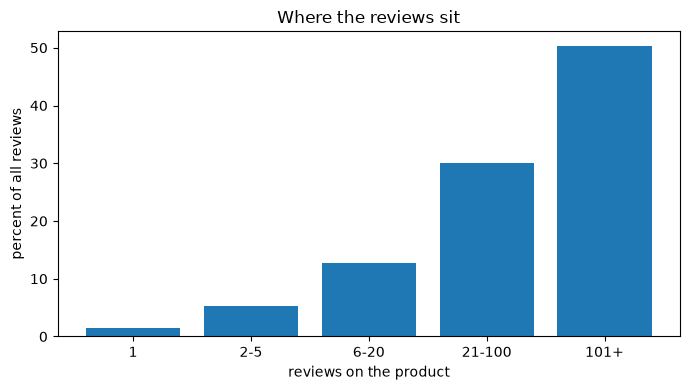

In [43]:
product_buckets = order_by(
    per_product.with_columns(count_bucket(pl.col("reviews")).alias("bucket"))
    .group_by("bucket")
    .agg(
        pl.len().alias("products"),
        pl.col("reviews").sum().alias("reviews"),
    ),
    "bucket",
    BUCKETS,
).with_columns(
    (pl.col("reviews") / total_reviews * 100).round(2).alias("percent_of_reviews")
)
from IPython.display import HTML, display
display(HTML(
    "<h3>Reviews grouped by product size</h3>"
    "<p>bucket is how many reviews the product has. products is how many products fall in the bucket. reviews is how many reviews those products contribute. percent_of_reviews is that contribution divided by the whole file.</p>"
))
print(product_buckets)

from IPython.display import HTML, display
display(HTML(
    "<h3>Where the reviews sit</h3>"
    "<p>The same percent_of_reviews, drawn as bars. A tall bar on the right means the busiest products hold most of the file.</p>"
))
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(product_buckets["bucket"].to_list(), product_buckets["percent_of_reviews"].to_list())
ax.set_xlabel("reviews on the product")
ax.set_ylabel("percent of all reviews")
ax.set_title("Where the reviews sit")
fig.tight_layout()
plt.show()

## Missing recommendation labels

Column-level missing counts are already in notebook 01. Here the question is whether a missing `recommendation_status` lines up with `is_buyer`, the rating band, or how many reviews the product has.

A missing label is not a class. These rows stay out of supervised loss.

In [44]:
from IPython.display import HTML, display
display(HTML(
    "<h3>Missing recommendation label by buyer flag</h3>"
    "<p>label_missing is true when recommendation_status is empty. rows is the count for that buyer flag. buyer_rows is every review with that flag. percent_within_buyer is rows divided by buyer_rows. Read the row where label_missing is true.</p>"
))
missing_by_buyer = (
    reviews.group_by("is_buyer", "label_missing")
    .agg(pl.len().alias("rows"))
    .collect()
)
buyer_totals = missing_by_buyer.group_by("is_buyer").agg(pl.col("rows").sum().alias("buyer_rows"))
missing_by_buyer = (
    missing_by_buyer.join(buyer_totals, on="is_buyer")
    .with_columns((pl.col("rows") / pl.col("buyer_rows") * 100).round(2).alias("percent_within_buyer"))
    .sort("is_buyer", "label_missing")
)
missing_by_buyer

is_buyer,label_missing,rows,buyer_rows,percent_within_buyer
bool,bool,u32,u32,f64
false,true,302181,302181,100.0
true,false,5261863,5854108,89.88
true,true,592245,5854108,10.12


In [45]:
from IPython.display import HTML, display
display(HTML(
    "<h3>Missing recommendation label by rating band</h3>"
    "<p>Same split, this time by rating band. low is 0 up to 2.5, medium is 2.5 up to 4, high is 4 through 5, and invalid is outside 0–5. percent_within_band is the share of that band with no recommendation label.</p>"
))
missing_by_band = (
    reviews.group_by("rating_band", "label_missing")
    .agg(pl.len().alias("rows"))
    .collect()
)
band_totals = missing_by_band.group_by("rating_band").agg(pl.col("rows").sum().alias("band_rows"))
missing_by_band = (
    missing_by_band.join(band_totals, on="rating_band")
    .with_columns((pl.col("rows") / pl.col("band_rows") * 100).round(2).alias("percent_within_band"))
    .sort("rating_band", "label_missing")
)
missing_by_band

rating_band,label_missing,rows,band_rows,percent_within_band
str,bool,u32,u32,f64
"""high""",false,3322400,4004905,82.96
"""high""",true,682505,4004905,17.04
"""invalid""",false,1,1,100.0
"""low""",false,991615,1092329,90.78
"""low""",true,100714,1092329,9.22
"""medium""",false,947847,1059054,89.5
"""medium""",true,111207,1059054,10.5


In [46]:
from IPython.display import HTML, display
display(HTML(
    "<h3>Missing recommendation label by product frequency</h3>"
    "<p>bucket is how many reviews the product has. percent_within_bucket, on the rows where label_missing is true, is the share of that bucket with no recommendation label. Compare those percents across buckets.</p>"
))
missing_by_frequency = (
    reviews.join(
        reviews.group_by("product_id").agg(pl.len().alias("product_reviews")),
        on="product_id",
    )
    .with_columns(count_bucket(pl.col("product_reviews")).alias("bucket"))
    .group_by("bucket", "label_missing")
    .agg(pl.len().alias("rows"))
    .collect()
)
bucket_totals = missing_by_frequency.group_by("bucket").agg(pl.col("rows").sum().alias("bucket_rows"))
missing_by_frequency = order_by(
    missing_by_frequency.join(bucket_totals, on="bucket").with_columns(
        (pl.col("rows") / pl.col("bucket_rows") * 100).round(2).alias("percent_within_bucket")
    ),
    "bucket",
    BUCKETS,
).sort("bucket", "label_missing")
missing_by_frequency

bucket,label_missing,rows,bucket_rows,percent_within_bucket
enum,bool,u32,u32,f64
"""1""",false,73275,91944,79.7
"""1""",true,18669,91944,20.3
"""2-5""",false,261579,322841,81.02
"""2-5""",true,61262,322841,18.98
"""6-20""",false,652870,788532,82.8
"""6-20""",true,135662,788532,17.2
"""21-100""",false,1575146,1854574,84.93
"""21-100""",true,279428,1854574,15.07
"""101+""",false,2698993,3098398,87.11


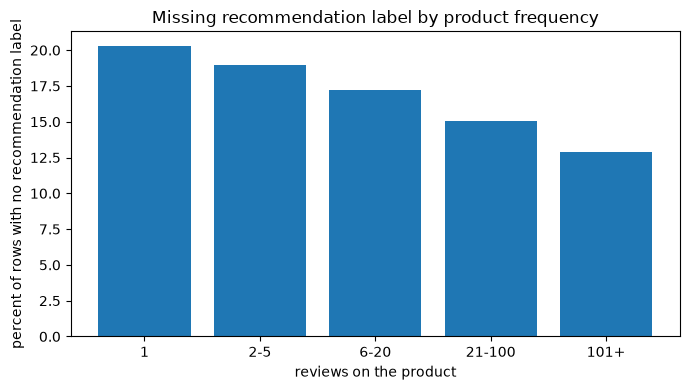

In [47]:
from IPython.display import HTML, display
display(HTML(
    "<h3>Missing labels across product sizes</h3>"
    "<p>Each bar is the percent of reviews in that product-size bucket whose recommendation label is empty. It is percent_within_bucket for label_missing = true.</p>"
))
missing_only = missing_by_frequency.filter(pl.col("label_missing"))
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(
    [str(bucket) for bucket in missing_only["bucket"].to_list()],
    missing_only["percent_within_bucket"].to_list(),
)
ax.set_xlabel("reviews on the product")
ax.set_ylabel("percent of rows with no recommendation label")
ax.set_title("Missing recommendation label by product frequency")
fig.tight_layout()
plt.show()

## Recommendation classes, rating bands, and raw rate

The recommendation head trains on the labeled rows only. The band head uses every row whose rate falls inside [0, 5]. The raw rate is the source of the band. It is not a model input: it has many distinct values, including fractions, and a score of 5 is not five times a score of 1.

In [48]:
from IPython.display import HTML, display
display(HTML(
    "<h3>Recommendation classes</h3>"
    "<p>null is a missing label, not a fourth class. percent_of_rows divides by every parsed review. percent_of_labeled divides by reviews that have a label, and is empty on the null row.</p>"
))
recommendation_counts = (
    reviews.group_by("recommendation_status")
    .agg(pl.len().alias("rows"))
    .sort("rows", descending=True)
    .collect()
)
labeled_rows = int(
    recommendation_counts.filter(pl.col("recommendation_status").is_not_null())["rows"].sum()
)
recommendation_counts = recommendation_counts.with_columns(
    (pl.col("rows") / total_reviews * 100).round(2).alias("percent_of_rows"),
    pl.when(pl.col("recommendation_status").is_null())
    .then(None)
    .otherwise((pl.col("rows") / labeled_rows * 100).round(2))
    .alias("percent_of_labeled"),
)
recommendation_counts

recommendation_status,rows,percent_of_rows,percent_of_labeled
str,u32,f64,f64
"""recommended""",4162839,67.62,79.11
null,894426,14.53,null
"""no_idea""",594121,9.65,11.29
"""not_recommended""",504903,8.2,9.6


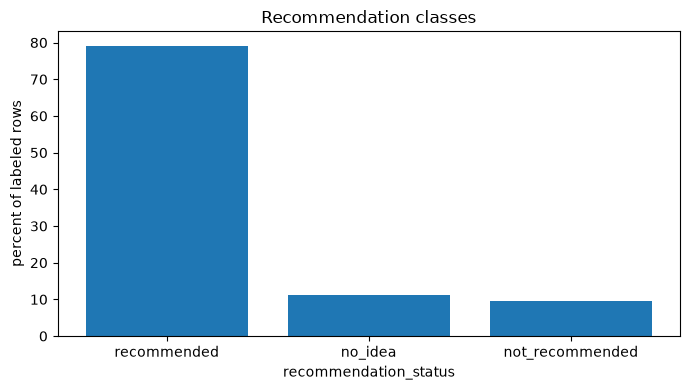

In [49]:
from IPython.display import HTML, display
display(HTML(
    "<h3>Labeled recommendation classes</h3>"
    "<p>Bars are the three classes that have a label. The height is percent_of_labeled, so reviews with no label are not in the chart.</p>"
))
labeled_counts = recommendation_counts.filter(
    pl.col("recommendation_status").is_in(LABELS)
).with_columns(pl.col("recommendation_status").cast(pl.Enum(LABELS))).sort("recommendation_status")

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(
    labeled_counts["recommendation_status"].to_list(),
    labeled_counts["percent_of_labeled"].to_list(),
)
ax.set_xlabel("recommendation_status")
ax.set_ylabel("percent of labeled rows")
ax.set_title("Recommendation classes")
fig.tight_layout()
plt.show()

In [50]:
from IPython.display import HTML, display
display(HTML(
    "<h3>Raw rate</h3>"
    "<p>min and max are the smallest and largest stored rates, including values outside 0–5. q25 through q99 are percentiles. n_unique is how many distinct rates exist. fractional_rows counts rates that are not whole numbers, and fractional_percent divides that by all rows. out_of_range counts rates outside 0–5. rate_zero counts scores of exactly 0, which stay in the low band.</p>"
))
rate_stats = reviews.select(
    pl.col("rate").min().alias("min"),
    pl.col("rate").max().alias("max"),
    pl.col("rate").mean().round(4).alias("mean"),
    pl.col("rate").median().alias("median"),
    pl.col("rate").std().round(4).alias("std"),
    pl.col("rate").quantile(0.25).alias("q25"),
    pl.col("rate").quantile(0.75).alias("q75"),
    pl.col("rate").quantile(0.90).alias("q90"),
    pl.col("rate").quantile(0.95).alias("q95"),
    pl.col("rate").quantile(0.99).alias("q99"),
    pl.col("rate").n_unique().alias("n_unique"),
    (pl.col("rate") != pl.col("rate").floor()).sum().alias("fractional_rows"),
    ((pl.col("rate") < 0) | (pl.col("rate") > 5)).sum().alias("out_of_range"),
    (pl.col("rate") == 0).sum().alias("rate_zero"),
    pl.len().alias("rows"),
).collect().with_columns(
    (pl.col("fractional_rows") / pl.col("rows") * 100).round(2).alias("fractional_percent")
)
rate_stats

min,max,mean,median,std,q25,…,n_unique,fractional_rows,out_of_range,rate_zero,rows,fractional_percent
f64,f64,f64,f64,f64,f64,…,u32,u32,u32,u32,u32,f64
0.0,2500.0,3.6483,4.0,1.8619,3.0,…,178,228128,1,529098,6156289,3.71


In [51]:
from IPython.display import HTML, display
display(HTML(
    "<h3>Rating bands</h3>"
    "<p>low is 0 up to but not including 2.5, medium is 2.5 up to but not including 4, and high is 4 through 5. invalid is outside 0–5. percent_of_rows divides by every parsed review.</p>"
))
band_counts = (
    reviews.group_by("rating_band")
    .agg(pl.len().alias("rows"))
    .collect()
    .with_columns((pl.col("rows") / total_reviews * 100).round(2).alias("percent_of_rows"))
)
band_counts = order_by(band_counts, "rating_band", BANDS + ["invalid"])
band_counts

rating_band,rows,percent_of_rows
enum,u32,f64
"""low""",1092329,17.74
"""medium""",1059054,17.2
"""high""",4004905,65.05
"""invalid""",1,0.0


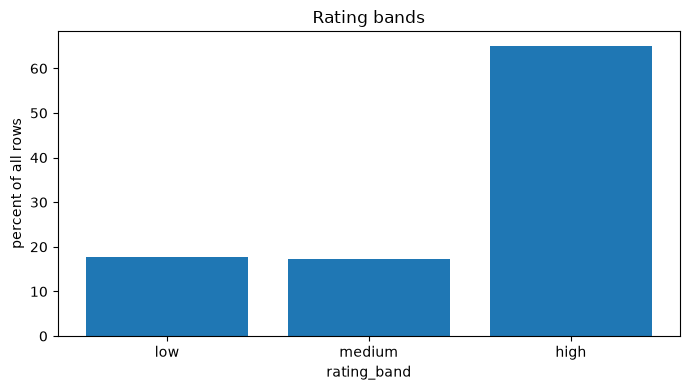

In [52]:
from IPython.display import HTML, display
display(HTML(
    "<h3>Valid rating bands</h3>"
    "<p>The three bands a model can learn. invalid is left off the chart because a rate outside 0–5 is not a training class.</p>"
))
valid_bands = band_counts.filter(pl.col("rating_band").is_in(BANDS))
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(
    [str(band) for band in valid_bands["rating_band"].to_list()],
    valid_bands["percent_of_rows"].to_list(),
)
ax.set_xlabel("rating_band")
ax.set_ylabel("percent of all rows")
ax.set_title("Rating bands")
fig.tight_layout()
plt.show()

In [53]:
from IPython.display import HTML, display
display(HTML(
    "<h3>Raw rate inside each recommendation value</h3>"
    "<p>mean_rate and median_rate are the numeric rate for that recommendation_status, including the null label. A higher mean means that group gave higher scores.</p>"
))
rate_by_label = (
    reviews.group_by("recommendation_status")
    .agg(
        pl.len().alias("rows"),
        pl.col("rate").mean().round(3).alias("mean_rate"),
        pl.col("rate").median().alias("median_rate"),
    )
    .sort("rows", descending=True)
    .collect()
)
rate_by_label

recommendation_status,rows,mean_rate,median_rate
str,u32,f64,f64
"""recommended""",4162839,3.934,4.0
null,894426,4.041,4.0
"""no_idea""",594121,2.923,3.0
"""not_recommended""",504903,1.448,1.0


In [54]:
from IPython.display import HTML, display
display(HTML(
    "<h3>Rating band inside each recommendation class</h3>"
    "<p>Only reviews that have a recommendation label. label_rows is the size of that class. percent_within_label is the share of the class that falls in the band.</p>"
))
band_by_label = (
    reviews.filter(pl.col("recommendation_status").is_not_null())
    .group_by("recommendation_status", "rating_band")
    .agg(pl.len().alias("rows"))
    .collect()
)
label_totals = band_by_label.group_by("recommendation_status").agg(
    pl.col("rows").sum().alias("label_rows")
)
band_by_label = band_by_label.join(label_totals, on="recommendation_status").with_columns(
    (pl.col("rows") / pl.col("label_rows") * 100).round(2).alias("percent_within_label")
)
band_by_label.sort("recommendation_status", "rating_band")

recommendation_status,rating_band,rows,label_rows,percent_within_label
str,str,u32,u32,f64
"""no_idea""","""high""",101844,594121,17.14
"""no_idea""","""low""",104215,594121,17.54
"""no_idea""","""medium""",388062,594121,65.32
"""not_recommended""","""high""",12635,504903,2.5
"""not_recommended""","""low""",424398,504903,84.06
"""not_recommended""","""medium""",67870,504903,13.44
"""recommended""","""high""",3207921,4162839,77.06
"""recommended""","""invalid""",1,4162839,0.0
"""recommended""","""low""",463002,4162839,11.12


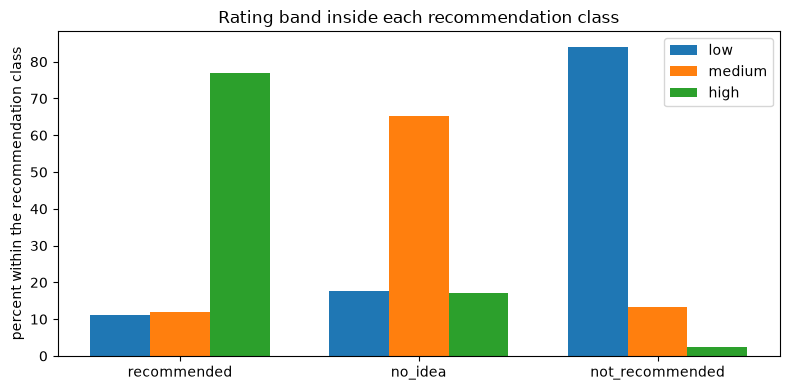

In [55]:
from IPython.display import HTML, display
display(HTML(
    "<h3>Band mix of each recommendation class</h3>"
    "<p>Each group of bars is one recommendation class. The three bars are low, medium, and high as a percent of that class. The legend names the band.</p>"
))
width = 0.25
x = np.arange(len(LABELS))
fig, ax = plt.subplots(figsize=(8, 4))
for i, band_name in enumerate(BANDS):
    heights = []
    for label in LABELS:
        match = band_by_label.filter(
            (pl.col("recommendation_status") == label) & (pl.col("rating_band") == band_name)
        )
        heights.append(float(match["percent_within_label"][0]) if match.height else 0.0)
    ax.bar(x + (i - 1) * width, heights, width, label=band_name)
ax.set_xticks(x, LABELS)
ax.set_ylabel("percent within the recommendation class")
ax.set_title("Rating band inside each recommendation class")
ax.legend()
fig.tight_layout()
plt.show()

## Body length

Character length counts Unicode characters, so a Persian letter is one character. Word length splits the normalized body on spaces. Empty bodies are excluded from the percentiles and reported on their own.

The encoder cap is 512 tokens, not 512 words. ParsBERT can split one Persian word into several pieces, so the word percentiles are a lower bound on token length. They still show whether the cap cuts a thin tail or a large share of reviews.

In [56]:
from IPython.display import HTML, display
display(HTML(
    "<h3>Length of non-empty review bodies</h3>"
    "<p>rows leaves out bodies that are blank after whitespace cleanup. char columns count Unicode characters, so one Persian letter is one character. word columns count words split on spaces, not encoder tokens. p50 is the median. p95 means 95 percent of bodies are at or below that length. The last columns count bodies that are very short or very long.</p>"
))
with_body = reviews.filter(pl.col("body_norm") != "")
length_stats = with_body.select(
    pl.len().alias("rows"),
    pl.col("char_len").min().alias("char_min"),
    pl.col("char_len").median().alias("char_p50"),
    pl.col("char_len").quantile(0.75).alias("char_p75"),
    pl.col("char_len").quantile(0.90).alias("char_p90"),
    pl.col("char_len").quantile(0.95).alias("char_p95"),
    pl.col("char_len").quantile(0.99).alias("char_p99"),
    pl.col("char_len").max().alias("char_max"),
    pl.col("word_len").min().alias("word_min"),
    pl.col("word_len").mean().round(2).alias("word_mean"),
    pl.col("word_len").median().alias("word_p50"),
    pl.col("word_len").quantile(0.75).alias("word_p75"),
    pl.col("word_len").quantile(0.90).alias("word_p90"),
    pl.col("word_len").quantile(0.95).alias("word_p95"),
    pl.col("word_len").quantile(0.99).alias("word_p99"),
    pl.col("word_len").quantile(0.999).alias("word_p999"),
    pl.col("word_len").max().alias("word_max"),
    (pl.col("word_len") <= 1).sum().alias("words_at_most_1"),
    (pl.col("word_len") <= 3).sum().alias("words_at_most_3"),
    (pl.col("char_len") <= 10).sum().alias("chars_at_most_10"),
    (pl.col("word_len") >= 128).sum().alias("words_at_least_128"),
    (pl.col("word_len") >= 256).sum().alias("words_at_least_256"),
    (pl.col("word_len") >= 512).sum().alias("words_at_least_512"),
).collect()
length_stats

rows,char_min,char_p50,char_p75,char_p90,char_p95,…,words_at_most_1,words_at_most_3,chars_at_most_10,words_at_least_128,words_at_least_256,words_at_least_512
u32,u32,f64,f64,f64,f64,…,u32,u32,u32,u32,u32,u32
6155652,1,29.0,57.0,106.0,152.0,…,453793,1675526,827860,7527,803,69


In [57]:
length_by_label = (
    with_body.group_by("recommendation_status")
    .agg(
        pl.len().alias("rows"),
        pl.col("word_len").median().alias("median_words"),
        pl.col("word_len").quantile(0.95).alias("p95_words"),
        pl.col("char_len").median().alias("median_chars"),
        pl.col("char_len").quantile(0.95).alias("p95_chars"),
    )
    .sort("rows", descending=True)
    .collect()
)
from IPython.display import HTML, display
display(HTML(
    "<h3>Length by recommendation label</h3>"
    "<p>One row per recommendation_status, including a missing label. median_words is the typical length of that group. p95_words is the long end. char columns are Unicode characters.</p>"
))
print(length_by_label)

length_by_band = (
    with_body.group_by("rating_band")
    .agg(
        pl.len().alias("rows"),
        pl.col("word_len").median().alias("median_words"),
        pl.col("word_len").quantile(0.95).alias("p95_words"),
    )
    .collect()
)
length_by_band = order_by(length_by_band, "rating_band", BANDS + ["invalid"])
from IPython.display import HTML, display
display(HTML(
    "<h3>Length by rating band</h3>"
    "<p>The same word lengths, split by rating band instead of recommendation label. invalid is the rate outside 0–5.</p>"
))
length_by_band

shape: (4, 6)
┌───────────────────────┬─────────┬──────────────┬───────────┬──────────────┬───────────┐
│ recommendation_status ┆ rows    ┆ median_words ┆ p95_words ┆ median_chars ┆ p95_chars │
│ ---                   ┆ ---     ┆ ---          ┆ ---       ┆ ---          ┆ ---       │
│ str                   ┆ u32     ┆ f64          ┆ f64       ┆ f64          ┆ f64       │
╞═══════════════════════╪═════════╪══════════════╪═══════════╪══════════════╪═══════════╡
│ recommended           ┆ 4162417 ┆ 6.0          ┆ 28.0      ┆ 27.0         ┆ 136.0     │
│ null                  ┆ 894290  ┆ 5.0          ┆ 32.0      ┆ 25.0         ┆ 154.0     │
│ no_idea               ┆ 594078  ┆ 8.0          ┆ 38.0      ┆ 37.0         ┆ 180.0     │
│ not_recommended       ┆ 504867  ┆ 10.0         ┆ 45.0      ┆ 48.0         ┆ 216.0     │
└───────────────────────┴─────────┴──────────────┴───────────┴──────────────┴───────────┘


rating_band,rows,median_words,p95_words
enum,u32,f64,f64
"""low""",1092193,8.0,38.0
"""medium""",1058950,7.0,35.0
"""high""",4004508,5.0,28.0
"""invalid""",1,4.0,4.0


shape: (9, 3)
┌────────┬─────────┬─────────┐
│ bin    ┆ rows    ┆ percent │
│ ---    ┆ ---     ┆ ---     │
│ enum   ┆ u32     ┆ f64     │
╞════════╪═════════╪═════════╡
│ 1      ┆ 453793  ┆ 7.37    │
│ 2-3    ┆ 1221733 ┆ 19.85   │
│ 4-5    ┆ 1174681 ┆ 19.08   │
│ 6-10   ┆ 1521668 ┆ 24.72   │
│ 11-20  ┆ 1083274 ┆ 17.6    │
│ 21-40  ┆ 521716  ┆ 8.48    │
│ 41-80  ┆ 149257  ┆ 2.42    │
│ 81-160 ┆ 25853   ┆ 0.42    │
│ 161+   ┆ 3677    ┆ 0.06    │
└────────┴─────────┴─────────┘


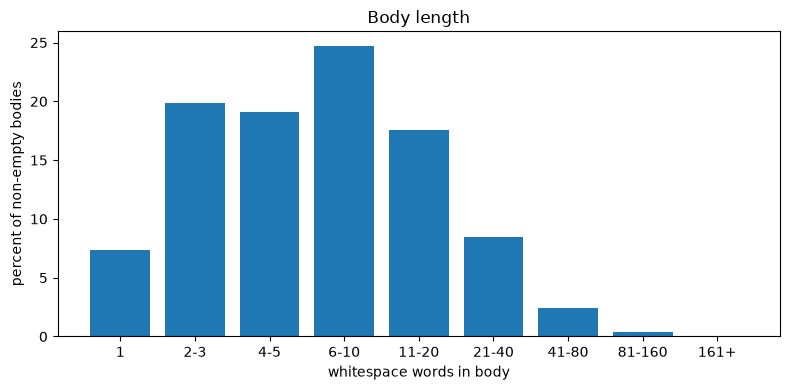

median words 6.0, p95 32.0, p99 62.0, max 908
bodies with at least 256 whitespace words: 803 (0.0130% of non-empty bodies)
A 512-token cap truncates the far tail. The p99 word count is the evidence for how thin that tail is, and it understates tokens because one Persian word can be several pieces.


In [58]:
word_bins = order_by(
    with_body.group_by(word_bin(pl.col("word_len")).alias("bin"))
    .agg(pl.len().alias("rows"))
    .collect(),
    "bin",
    WORD_BINS,
).with_columns((pl.col("rows") / pl.col("rows").sum() * 100).round(2).alias("percent"))
from IPython.display import HTML, display
display(HTML(
    "<h3>Word-count bins</h3>"
    "<p>bin is how many whitespace-separated words the body has. rows is how many non-empty bodies fall in the bin. percent divides by all non-empty bodies.</p>"
))
print(word_bins)

from IPython.display import HTML, display
display(HTML(
    "<h3>How long the reviews are</h3>"
    "<p>The same percents as bars. Most of the mass on the left means a typical review is short.</p>"
))
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar([str(bin_name) for bin_name in word_bins["bin"].to_list()], word_bins["percent"].to_list())
ax.set_xlabel("whitespace words in body")
ax.set_ylabel("percent of non-empty bodies")
ax.set_title("Body length")
fig.tight_layout()
plt.show()

from IPython.display import HTML, display
display(HTML(
    "<h3>What the length says about the 512-token cap</h3>"
    "<p>The first line is the median, the 95th percentile, the 99th percentile, and the longest body, in whitespace words. The second line counts bodies with at least 256 words. These are words, not encoder tokens: one Persian word can become several tokens, so the token length is longer than the word count.</p>"
))
rows_with_body = int(length_stats["rows"][0])
long_tail = int(length_stats["words_at_least_256"][0])
print(
    f"median words {length_stats['word_p50'][0]}, "
    f"p95 {length_stats['word_p95'][0]}, "
    f"p99 {length_stats['word_p99'][0]}, "
    f"max {length_stats['word_max'][0]}"
)
print(
    f"bodies with at least 256 whitespace words: {long_tail} "
    f"({100 * long_tail / rows_with_body:.4f}% of non-empty bodies)"
)
print(
    "A 512-token cap truncates the far tail. "
    "The p99 word count is the evidence for how thin that tail is, "
    "and it understates tokens because one Persian word can be several pieces."
)

## Repeated ids and repeated text

Notebook 01 dropped surplus ids on the four-column frame, after `recommendation_status` was already gone. This section checks the raw file: an id, or one normalized body, that carries more than one recommendation value or more than one rate.

A repeated short body can still be a real review of a different product. The conflict count is only the cases where that shared text does not share a label or a rate. Those rows must not be collapsed into one training example.

In [59]:
from IPython.display import HTML, display
display(HTML(
    "<h3>Review ids that appear more than once</h3>"
    "<p>ids_with_extra_copies counts ids that occur more than once. rows_in_those_ids counts every review that belongs to such an id, including the copy that would be kept. The last three columns count ids whose copies disagree on the recommendation label, the rate, or the body text.</p>"
))
id_groups = reviews.group_by("id").agg(
    pl.len().alias("n"),
    pl.col("recommendation_status").drop_nulls().n_unique().alias("n_rec"),
    pl.col("rate").n_unique().alias("n_rate"),
    pl.col("body_norm").n_unique().alias("n_body"),
)
id_summary = id_groups.select(
    (pl.col("n") > 1).sum().alias("ids_with_extra_copies"),
    pl.col("n").filter(pl.col("n") > 1).sum().alias("rows_in_those_ids"),
    ((pl.col("n") > 1) & (pl.col("n_rec") > 1)).sum().alias("ids_with_two_recommendations"),
    ((pl.col("n") > 1) & (pl.col("n_rate") > 1)).sum().alias("ids_with_two_rates"),
    ((pl.col("n") > 1) & (pl.col("n_body") > 1)).sum().alias("ids_with_two_bodies"),
).collect()
id_summary

ids_with_extra_copies,rows_in_those_ids,ids_with_two_recommendations,ids_with_two_rates,ids_with_two_bodies
u32,u32,u32,u32,u32
3226,6455,43,79,155


In [60]:
body_groups = (
    pl.scan_csv(RAW, null_values=NA_VALUES)
    .select("body", "recommendation_status", "rate", "product_id")
    .with_columns(
        pl.col("body")
        .fill_null("")
        .str.replace_all(r"\s+", " ")
        .str.strip_chars()
        .alias("body_norm")
    )
    .filter(pl.col("body_norm") != "")
    .group_by("body_norm")
    .agg(
        pl.len().alias("n"),
        pl.col("recommendation_status").drop_nulls().n_unique().alias("n_rec"),
        pl.col("recommendation_status").drop_nulls().unique().alias("labels"),
        pl.col("rate").n_unique().alias("n_rate"),
        pl.col("product_id").n_unique().alias("n_products"),
    )
)
body_summary = body_groups.select(
    pl.len().alias("distinct_bodies"),
    (pl.col("n") > 1).sum().alias("bodies_that_repeat"),
    pl.col("n").filter(pl.col("n") > 1).sum().alias("rows_in_repeated_bodies"),
    ((pl.col("n") > 1) & (pl.col("n_rec") > 1)).sum().alias("bodies_with_two_recommendations"),
    pl.col("n")
    .filter((pl.col("n") > 1) & (pl.col("n_rec") > 1))
    .sum()
    .alias("rows_with_two_recommendations"),
    ((pl.col("n") > 1) & (pl.col("n_rate") > 1)).sum().alias("bodies_with_two_rates"),
    pl.col("n").filter((pl.col("n") > 1) & (pl.col("n_rate") > 1)).sum().alias("rows_with_two_rates"),
).collect()
from IPython.display import HTML, display
display(HTML(
    "<h3>Repeated review text</h3>"
    "<p>distinct_bodies counts different texts after spaces and line breaks are collapsed. bodies_that_repeat counts texts that occur more than once. rows_in_repeated_bodies counts the reviews that use those texts. The remaining columns count texts, and the reviews that use them, when the copies do not share one recommendation value or one rate.</p>"
))
print(body_summary)

from IPython.display import HTML, display
display(HTML(
    "<h3>Most common texts that disagree on the label</h3>"
    "<p>The 15 repeated texts that carry more than one recommendation value, ordered by how often they appear. n is the number of reviews. labels lists the recommendation values on those reviews. n_products is how many products use that text. n_rate is how many distinct rates it has.</p>"
))
conflict_examples = (
    body_groups.filter((pl.col("n") > 1) & (pl.col("n_rec") > 1))
    .sort("n", descending=True)
    .head(15)
    .collect()
    .with_columns(pl.col("labels").list.sort())
)
conflict_examples

shape: (1, 7)
┌──────────────┬─────────────┬─────────────┬─────────────┬─────────────┬─────────────┬─────────────┐
│ distinct_bod ┆ bodies_that ┆ rows_in_rep ┆ bodies_with ┆ rows_with_t ┆ bodies_with ┆ rows_with_t │
│ ies          ┆ _repeat     ┆ eated_bodie ┆ _two_recomm ┆ wo_recommen ┆ _two_rates  ┆ wo_rates    │
│ ---          ┆ ---         ┆ s           ┆ endation…   ┆ dations     ┆ ---         ┆ ---         │
│ u32          ┆ u32         ┆ ---         ┆ ---         ┆ ---         ┆ u32         ┆ u32         │
│              ┆             ┆ u32         ┆ u32         ┆ u32         ┆             ┆             │
╞══════════════╪═════════════╪═════════════╪═════════════╪═════════════╪═════════════╪═════════════╡
│ 4034601      ┆ 193882      ┆ 2314933     ┆ 31409       ┆ 1609737     ┆ 117355      ┆ 2105785     │
└──────────────┴─────────────┴─────────────┴─────────────┴─────────────┴─────────────┴─────────────┘


body_norm,n,n_rec,labels,n_rate,n_products
str,u32,u32,list[str],u32,u32
"""عالی""",134693,3,"[""no_idea"", ""not_recommended"", ""recommended""]",33,60174
"""خوب بود""",90243,3,"[""no_idea"", ""not_recommended"", ""recommended""]",66,47518
"""خوبه""",83691,3,"[""no_idea"", ""not_recommended"", ""recommended""]",36,41497
"""خوب""",70705,3,"[""no_idea"", ""not_recommended"", ""recommended""]",22,39628
"""عالی بود""",30680,3,"[""no_idea"", ""not_recommended"", ""recommended""]",46,23398
"""عالیه""",23438,3,"[""no_idea"", ""not_recommended"", ""recommended""]",41,18294
"""خیلی خوب بود""",17628,3,"[""no_idea"", ""not_recommended"", ""recommended""]",52,14585
"""پیشنهاد میکنم""",15434,3,"[""no_idea"", ""not_recommended"", ""recommended""]",50,13212
"""معمولی""",15148,3,"[""no_idea"", ""not_recommended"", ""recommended""]",25,12136


## What this changes in the model

The cell below prints the decisions these tables support: class weights, the product-grouped split, the token cap, and keeping the raw rate out of the features. The sentences use the frames above, so they follow the file rather than a fixed claim.

In [61]:
from IPython.display import HTML, display
display(HTML(
    "<h3>What these counts change in the model</h3>"
    "<p>Five consequences, in order: class weights for the recommendation head, a split that keeps one product on one side, unlabeled rows kept out of supervised training, the rating band instead of the raw rate, and repeated texts that must not be merged into one label.</p>"
))
labeled = recommendation_counts.filter(pl.col("recommendation_status").is_not_null()).sort(
    "rows", descending=True
)
largest = labeled.row(0, named=True)
smallest = labeled.sort("rows").row(0, named=True)
print(
    f"{largest['recommendation_status']} is {largest['percent_of_labeled']}% of labeled rows. "
    f"{smallest['recommendation_status']} is {smallest['percent_of_labeled']}%. "
    "Score the recommendation head with macro F1 and class weights."
)

top_10 = concentration.row(1, named=True)
one_review = int(product_stats["products_with_one_review"][0])
print(
    f"{top_10['slice']} hold {top_10['percent_of_reviews']}% of reviews. "
    f"{one_review} products have a single review. "
    "Split by product_id so a product's reviews do not leak across train, validation, and test."
)

non_buyer = missing_by_buyer.filter((pl.col("is_buyer") == False) & pl.col("label_missing"))
non_buyer_missing = float(non_buyer["percent_within_buyer"][0])
print(
    f"Among non-buyers, {non_buyer_missing}% of rows have no recommendation label. "
    "Missing labels are a property of the row, not a fourth class, and they stay out of supervised loss."
)

print(
    f"rate has {int(rate_stats['n_unique'][0])} distinct values, "
    f"{float(rate_stats['fractional_percent'][0])}% of them fractional, "
    f"and {int(rate_stats['out_of_range'][0])} outside [0, 5]. "
    "Train the ordered band, not the raw number."
)

print(
    f"{int(body_summary['bodies_with_two_recommendations'][0])} repeated bodies "
    "carry more than one recommendation value, and "
    f"{int(body_summary['bodies_with_two_rates'][0])} carry more than one rate. "
    "Keep those rows. Do not merge a shared body into one label."
)

recommended is 79.11% of labeled rows. not_recommended is 9.6%. Score the recommendation head with macro F1 and class weights.
top 10% of products hold 67.12% of reviews. 91944 products have a single review. Split by product_id so a product's reviews do not leak across train, validation, and test.
Among non-buyers, 100.0% of rows have no recommendation label. Missing labels are a property of the row, not a fourth class, and they stay out of supervised loss.
rate has 178 distinct values, 3.71% of them fractional, and 1 outside [0, 5]. Train the ordered band, not the raw number.
31409 repeated bodies carry more than one recommendation value, and 117355 carry more than one rate. Keep those rows. Do not merge a shared body into one label.


## Characters inside the review text

The length section counted words after spaces and line breaks were collapsed. This section looks at the original `body`, because that collapse hides the line breaks, tabs, and repeated spaces.

A review is counted once for each mark it contains. One review can contain several. `matches` is how many times the pattern occurs. For a single character that is the character count. For a pattern such as two spaces in a row, it is the number of runs.

Arabic-script letters here include Persian. `ك` and `ي` are a different code point from Persian `ک` and `ی`, so they are counted on their own. Latin letters include brand names and model codes, not a separate English review.

In [62]:
from IPython.display import HTML, display

display(HTML(
    "<h3>What the raw review text contains</h3>"
    "<p>Each row is one kind of character or run in the original body. "
    "reviews is how many reviews contain it at least once. "
    "matches is how many times it occurs. "
    "The denominator is every parsed review, including empty bodies, which match nothing. "
    "A review with both a Persian digit and a Latin letter is counted in both rows.</p>"
))

raw = pl.col("body").fill_null("")
compact = raw.str.replace_all(r"\s+", "")
arabic_letter = r"[\u0621-\u063A\u0641-\u064A\u0671-\u06D3]"

marks = [
    ("ASCII digits 0-9", r"[0-9]"),
    ("Persian digits ۰-۹", r"[۰-۹]"),
    ("Arabic-Indic digits ٠-٩", r"[٠-٩]"),
    ("fullwidth digits ０-９", r"[０-９]"),
    ("Persian kaf or ye, ک or ی", r"[کی]"),
    ("Arabic kaf or ye, ك or ي or ى", r"[كيى]"),
    ("other Arabic letters mapped to Persian", r"[ةؤأإٱۀھ]"),
    ("Arabic-script letter, including Persian", arabic_letter),
    ("Latin letter", r"\p{Latin}"),
    ("Cyrillic letter", r"\p{Cyrillic}"),
    ("Hebrew letter", r"\p{Hebrew}"),
    ("Greek letter", r"\p{Greek}"),
    ("Armenian letter", r"\p{Armenian}"),
    ("Han character", r"\p{Han}"),
    ("Hangul syllable", r"\p{Hangul}"),
    ("emoji", r"\p{Extended_Pictographic}"),
    ("half-space, ZWNJ U+200C", "\u200c"),
    ("two half-spaces in a row", "\u200c{2,}"),
    ("half-space at an end or beside a space", r"(^|\s)\u200c|\u200c(\s|$)"),
    ("zero-width space", "\u200b"),
    ("zero-width joiner", "\u200d"),
    ("byte-order mark", "\ufeff"),
    ("line break", r"[\r\n]"),
    ("tab", r"\t"),
    ("no-break space", "\u00a0"),
    ("two or more ordinary spaces", r" {2,}"),
    ("tatweel", "\u0640"),
    ("Arabic diacritic", r"[\u064B-\u065F\u0670\u06D6-\u06ED]"),
    ("Arabic presentation form", r"[\uFB50-\uFDFF\uFE70-\uFEFE]"),
]

totals = reviews.select(
    pl.len().alias("parsed_rows"),
    (compact == "").sum().alias("empty_after_space_collapse"),
    compact.str.contains(r"^(?:\p{Extended_Pictographic}|\uFE0F|\u200D)+$").sum().alias("emoji_only"),
    (
        raw.str.contains(r"[0-9]")
        & raw.str.contains(r"[۰-۹]")
    ).sum().alias("both_ascii_and_persian_digits"),
    (
        raw.str.contains(r"[0-9]")
        & raw.str.contains(r"[٠-٩]")
    ).sum().alias("both_ascii_and_arabic_digits"),
    (
        raw.str.contains(r"[۰-۹]")
        & raw.str.contains(r"[٠-٩]")
    ).sum().alias("both_persian_and_arabic_digits"),
    (
        raw.str.contains(r"\p{Latin}")
        & raw.str.contains(arabic_letter)
    ).sum().alias("latin_and_arabic_script"),
    (
        raw.str.contains(r"\p{Latin}")
        & ~raw.str.contains(arabic_letter)
        & (compact != "")
    ).sum().alias("latin_without_arabic_script"),
    *[
        raw.str.contains(pattern).sum().alias(f"reviews_{index}")
        for index, (_, pattern) in enumerate(marks)
    ],
    *[
        raw.str.count_matches(pattern).sum().alias(f"matches_{index}")
        for index, (_, pattern) in enumerate(marks)
    ],
).collect()

parsed_rows = int(totals["parsed_rows"][0])
character_marks = pl.DataFrame(
    {
        "mark": [label for label, _ in marks],
        "reviews": [int(totals[f"reviews_{index}"][0]) for index in range(len(marks))],
        "matches": [int(totals[f"matches_{index}"][0]) for index in range(len(marks))],
    }
).with_columns(
    (pl.col("reviews") / parsed_rows * 100).round(2).alias("percent_of_reviews")
)
character_marks

def count(name: str) -> int:
    return int(totals[name][0])

def reviews_for(label: str) -> int:
    return int(character_marks.filter(pl.col("mark") == label)["reviews"][0])

def percent(n: int) -> str:
    return f"{100 * n / parsed_rows:.2f}%"

print(
    f"{count('emoji_only')} reviews ({percent(count('emoji_only'))}) "
    "are only emoji once spaces are removed. "
    "An emoji-only body is still a review, so the text pass should not delete emoji before that choice is tested."
)
print(
    f"ASCII digits appear in {percent(reviews_for('ASCII digits 0-9'))} of reviews, "
    f"Persian digits in {percent(reviews_for('Persian digits ۰-۹'))}, "
    f"and Arabic-Indic digits in {percent(reviews_for('Arabic-Indic digits ٠-٩'))}. "
    f"{count('both_ascii_and_persian_digits')} reviews use both ASCII and Persian digits, "
    f"{count('both_ascii_and_arabic_digits')} use both ASCII and Arabic-Indic, "
    f"and {count('both_persian_and_arabic_digits')} use both Persian and Arabic-Indic. "
    "Those three digit scripts are different code points, so a tokenizer will not treat 5, ۵, and ٥ as one character until they are folded."
)
print(
    f"Arabic kaf or ye (ك, ي, ى) appears in {percent(reviews_for('Arabic kaf or ye, ك or ي or ى'))} of reviews. "
    f"Persian kaf or ye (ک, ی) appears in {percent(reviews_for('Persian kaf or ye, ک or ی'))}. "
    "Mapping the Arabic forms onto the Persian letters is what lets those spellings share a subword."
)
print(
    f"Latin letters appear in {percent(reviews_for('Latin letter'))} of reviews. "
    f"{count('latin_and_arabic_script')} of those also contain an Arabic-script letter, "
    f"and {count('latin_without_arabic_script')} do not. "
    "The Latin slice is brand names and model codes mixed into Persian, not a second corpus."
)
other_scripts = [
    "Cyrillic letter",
    "Hebrew letter",
    "Greek letter",
    "Armenian letter",
    "Han character",
    "Hangul syllable",
]
other_hits = [(label, reviews_for(label)) for label in other_scripts if reviews_for(label) > 0]
if other_hits:
    detail = ", ".join(f"{label} in {n} reviews ({percent(n)})" for label, n in other_hits)
    print(f"Other scripts are rare. {detail}.")
else:
    print("Cyrillic, Hebrew, Greek, Armenian, Han, and Hangul do not appear.")
print(
    f"A half-space (ZWNJ) appears in {percent(reviews_for('half-space, ZWNJ U+200C'))} of reviews. "
    f"{reviews_for('two half-spaces in a row')} reviews have two half-spaces in a row, "
    f"and {reviews_for('half-space at an end or beside a space')} have a half-space at an end or next to a space. "
    "One half-space inside a word is part of the Persian spelling. The repeated and edge ones are the copies a cleaner can drop without joining separate words."
)
print(
    f"Line breaks appear in {percent(reviews_for('line break'))} of reviews, "
    f"tabs in {percent(reviews_for('tab'))}, "
    f"and a run of two or more ordinary spaces in {percent(reviews_for('two or more ordinary spaces'))}. "
    "Those are the whitespace forms the cleaner collapses. "
    f"A no-break space appears in {reviews_for('no-break space')} reviews, "
    f"a zero-width space in {reviews_for('zero-width space')}, "
    f"a zero-width joiner in {reviews_for('zero-width joiner')}, "
    f"and a byte-order mark in {reviews_for('byte-order mark')}."
)


172 reviews (0.00%) are only emoji once spaces are removed. An emoji-only body is still a review, so the text pass should not delete emoji before that choice is tested.
ASCII digits appear in 1.56% of reviews, Persian digits in 3.17%, and Arabic-Indic digits in 0.02%. 2796 reviews use both ASCII and Persian digits, 13 use both ASCII and Arabic-Indic, and 166 use both Persian and Arabic-Indic. Those three digit scripts are different code points, so a tokenizer will not treat 5, ۵, and ٥ as one character until they are folded.
Arabic kaf or ye (ك, ي, ى) appears in 0.82% of reviews. Persian kaf or ye (ک, ی) appears in 90.13%. Mapping the Arabic forms onto the Persian letters is what lets those spellings share a subword.
Latin letters appear in 0.65% of reviews. 36765 of those also contain an Arabic-script letter, and 3307 do not. The Latin slice is brand names and model codes mixed into Persian, not a second corpus.
Other scripts are rare. Cyrillic letter in 1 reviews (0.00%), Hebrew lett